# 02 · Исследовательский анализ (EDA)

Работаем с очищенными таблицами из [01_data_cleaning](01_data_cleaning.ipynb).

**Определения, которые используются везде ниже:**
- **Лид** — сделка (потенциальная сделка) в таблице Deals после удаления технических дублей.
- **Студент (успешная сделка)** — `Payment Done` + заполнен `Months of study` + не демо-доступ.
- **C1 (конверсия)** = студенты / лиды.
- **Выручка** — сумма, фактически полученная к дате выгрузки (см. формулу в 01).

План по ТЗ: описательная статистика → временные ряды → кампании и источники → отдел продаж →
платежи и продукты → география → выводы.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent / "src"))
import cleaning as etl
import viz
from viz import PRIMARY, ACCENT, GOOD, MUTED, save, pct_axis, eur_axis

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)

data = etl.load_clean()
deals, calls, spend, contacts = data["Deals"], data["Calls"], data["Spend"], data["Contacts"]
students = deals[deals["is_student"]]
OBS = dict(observed=True)
print(f"Лидов: {len(deals):,} | студентов: {len(students):,} | C1: {deals['is_student'].mean():.2%}")
print(f"Период: {deals['created_time'].min():%d.%m.%Y} – {deals['created_time'].max():%d.%m.%Y}")
print(f"Выручка: €{students['revenue'].sum():,.0f} | рекламный бюджет: €{spend['spend'].sum():,.0f}")

Лидов: 19,822 | студентов: 837 | C1: 4.22%
Период: 03.07.2023 – 21.06.2024
Выручка: €3,578,345 | рекламный бюджет: €149,523


## 1. Описательная статистика
### 1.1 Числовые поля: среднее, медиана, мода, диапазон

In [2]:
def describe_num(s: pd.Series) -> pd.Series:
    s = s.dropna()
    mode = s.mode()
    return pd.Series({
        "n": len(s), "mean": s.mean(), "median": s.median(),
        "mode": mode.iloc[0] if len(mode) else np.nan,
        "min": s.min(), "max": s.max(), "range": s.max() - s.min(), "std": s.std(),
    })

numeric = {
    "Deals · offer_total_amount (студенты), €": students["offer_total_amount"],
    "Deals · initial_amount_paid (студенты), €": students["initial_amount_paid"],
    "Deals · revenue на студента, €": students["revenue"],
    "Deals · months_of_study": students["months_of_study"],
    "Deals · course_duration, мес.": students["course_duration"],
    "Deals · deal_cycle_days (студенты)": students["deal_cycle_days"],
    "Deals · SLA, часы": deals["sla_sec"] / 3600,
    "Calls · duration_sec": calls["duration_sec"],
    "Spend · spend в день по строке, €": spend["spend"],
    "Spend · clicks": spend["clicks"],
    "Spend · impressions": spend["impressions"],
}
stats = pd.DataFrame({k: describe_num(v) for k, v in numeric.items()}).T
stats

,n,mean,median,mode,min,max,range,std
"Deals · offer_total_amount (студенты), €",837.00,"7,564.40","11,000.00","11,000.00","2,000.00","11,500.00","9,500.00","3,736.30"
"Deals · initial_amount_paid (студенты), €",837.00,"1,157.05","1,000.00","1,000.00",100.00,"11,000.00","10,900.00","1,457.12"
"Deals · revenue на студента, €",837.00,"4,275.20","3,350.00","2,000.00",100.00,"11,500.00","11,400.00","2,957.62"
Deals · months_of_study,837.00,5.44,5.00,6.00,0.00,11.00,11.00,2.91
"Deals · course_duration, мес.",837.00,10.18,11.00,11.00,6.00,11.00,5.00,1.85
Deals · deal_cycle_days (студенты),513.00,33.45,17.00,8.00,0.00,305.00,305.00,42.79
"Deals · SLA, часы","14,995.00",30.97,5.50,0.17,0.00,"7,474.57","7,474.57",201.81
Calls · duration_sec,"95,791.00",164.98,8.00,0.00,0.00,"7,625.00","7,625.00",401.41
"Spend · spend в день по строке, €","19,862.00",7.53,0.74,0.00,0.00,774.00,774.00,27.33
Spend · clicks,"19,862.00",25.10,2.00,0.00,0.00,"2,415.00","2,415.00",87.03


**Интерпретация:**
- **Стоимость курса** у студентов: мода и медиана — €11 000 (11-месячные Digital Marketing и UX/UI),
  среднее ниже (~€7.5k) из-за дешёвых пакетов и 6-месячного Web Developer. Распределение бимодальное —
  среднее здесь плохо описывает «типичного» студента, корректнее смотреть медиану и разрез по продукту.
- **Первый платёж**: мода €1 000 — стандартный вход в рассрочку.
- **Цикл сделки**: медиана 17 дней, среднее 33 — длинный правый хвост (до 305 дней): часть клиентов
  «дозревает» месяцами.
- **SLA**: медиана ~5.5 ч, среднее ~31 ч — единичные заявки ждут ответа неделями. Это первый кандидат в точки роста.
- **Звонки**: медиана 8 секунд, среднее 165 — большинство звонков — недозвоны; реальный разговор встречается реже.

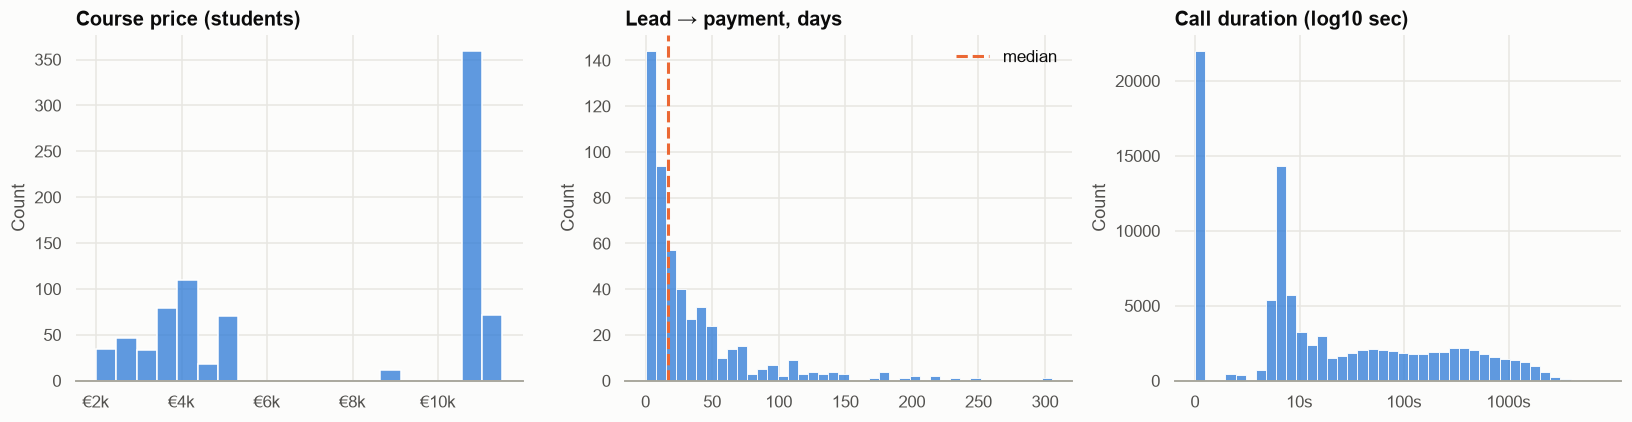

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(students["offer_total_amount"], bins=20, ax=axes[0], color=PRIMARY)
axes[0].set_title("Course price (students)"); eur_axis(axes[0], "x"); axes[0].set_xlabel("")
sns.histplot(students["deal_cycle_days"].dropna(), bins=40, ax=axes[1], color=PRIMARY)
axes[1].axvline(students["deal_cycle_days"].median(), color=ACCENT, ls="--", lw=2, label="median")
axes[1].set_title("Lead → payment, days"); axes[1].legend(frameon=False); axes[1].set_xlabel("")
sns.histplot(np.log10(calls["duration_sec"] + 1), bins=40, ax=axes[2], color=PRIMARY)
axes[2].set_title("Call duration (log10 sec)"); axes[2].set_xlabel("")
axes[2].set_xticks([0, 1, 2, 3]); axes[2].set_xticklabels(["0", "10s", "100s", "1000s"])
plt.tight_layout(); save(fig, "02_distributions"); plt.show()

### 1.2 Категориальные поля: качество, стадия, источник, продукт

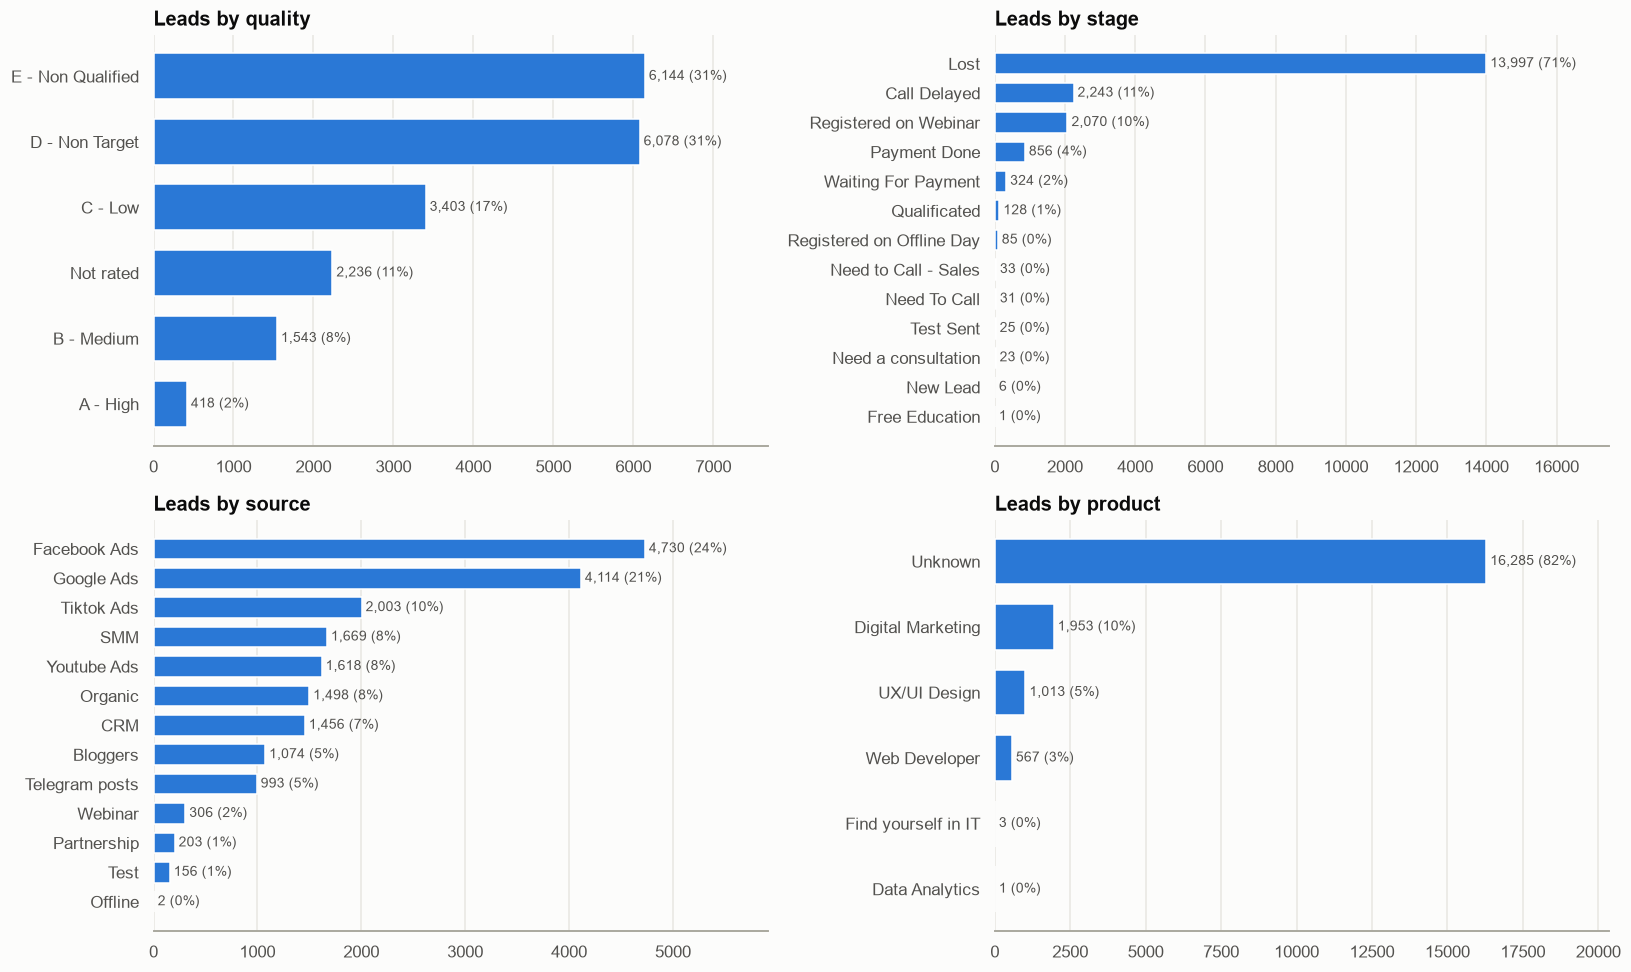

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["quality", "stage", "source", "product"]):
    vc = deals[col].value_counts()
    vc = vc[vc > 0].sort_values()
    ax.barh(vc.index.astype(str), vc.values, color=PRIMARY, height=0.7)
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v:,} ({v / len(deals):.0%})", va="center", fontsize=9, color=viz.TEXT_2)
    ax.set_title(f"Leads by {col}"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vc.max() * 1.25)
plt.tight_layout(); save(fig, "02_categorical"); plt.show()

In [5]:
cat_conv = []
for col in ["quality", "source", "product", "education_type"]:
    g = deals.groupby(col, **OBS).agg(leads=("id", "size"), students=("is_student", "sum"))
    g["C1"] = g["students"] / g["leads"]
    g.index = pd.MultiIndex.from_product([[col], g.index.astype(str)])
    cat_conv.append(g)
pd.concat(cat_conv).style.format({"C1": "{:.1%}", "leads": "{:,}"}).background_gradient(subset="C1", cmap="Blues")

**Выводы по категориям:**
- **Стадия:** 71% лидов в `Lost`, до оплаты доходит 4.3%. Главные причины потерь (ниже) — «не отвечает» и
  «перестал отвечать» (40% проигранных сделок, вместе с неверным номером — 51%): это проблема **дозвона и скорости реакции**, а не цены.
- **Качество:** класс A конвертируется в 34% случаев, B — 21%, C — 10%, D/E — почти 0. Оценка менеджера
  хорошо предсказывает оплату, поэтому доля A+B — надёжная *опережающая* метрика для A/B-теста.
- **Продукт:** у 82% лидов продукт не указан (не дошли до консультации). Среди указанных лидеры —
  Digital Marketing (≈55% продаж), UX/UI Design, Web Developer.

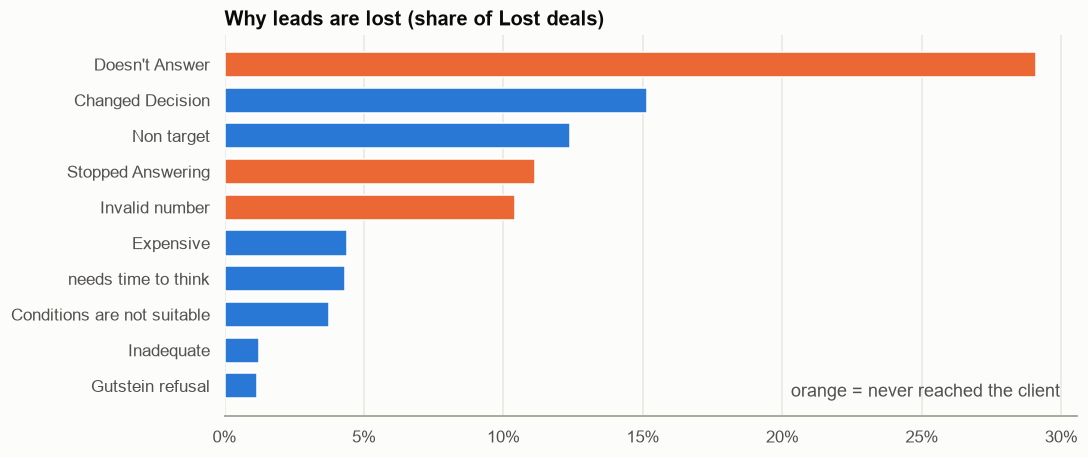

In [6]:
lost = deals.loc[deals["stage"].eq("Lost"), "lost_reason"].value_counts(normalize=True).head(10).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [ACCENT if r in ("Doesn't Answer", "Stopped Answering", "Invalid number") else PRIMARY for r in lost.index]
ax.barh(lost.index.astype(str), lost.values, color=colors, height=0.7)
pct_axis(ax, "x"); ax.set_title("Why leads are lost (share of Lost deals)")
ax.text(0.98, 0.05, "orange = never reached the client", transform=ax.transAxes, ha="right", color=viz.TEXT_2)
ax.grid(axis="y", visible=False)
save(fig, "02_lost_reasons"); plt.show()

## 2. Анализ временных рядов
### 2.1 Динамика создания сделок и связь со звонками

In [7]:
monthly = deals.groupby("month").agg(leads=("id", "size"), students=("is_student", "sum"),
                                     revenue=("revenue", "sum"))
monthly["calls"] = calls.groupby(calls["call_start_time"].dt.to_period("M").dt.to_timestamp()).size()
monthly["spend"] = spend.groupby(spend["date"].dt.to_period("M").dt.to_timestamp())["spend"].sum()
monthly["C1"] = monthly["students"] / monthly["leads"]
monthly["calls_per_lead"] = monthly["calls"] / monthly["leads"]
monthly.style.format({"C1": "{:.1%}", "revenue": "€{:,.0f}", "spend": "€{:,.0f}", "calls_per_lead": "{:.1f}"})

,leads,students,revenue,calls,spend,C1,calls_per_lead
month,,,,,,,
2023-07-01 00:00:00,612,9,"€54,240",1935,"€6,062",1.5%,3.2
2023-08-01 00:00:00,931,48,"€275,840",4251,"€9,034",5.2%,4.6
2023-09-01 00:00:00,976,49,"€339,735",5156,"€8,711",5.0%,5.3
2023-10-01 00:00:00,1462,77,"€456,325",7102,"€11,808",5.3%,4.9
2023-11-01 00:00:00,1767,102,"€593,935",7169,"€10,891",5.8%,4.1
2023-12-01 00:00:00,1661,103,"€499,680",7099,"€12,186",6.2%,4.3
2024-01-01 00:00:00,2046,114,"€441,640",9778,"€12,584",5.6%,4.8
2024-02-01 00:00:00,1979,72,"€228,150",9591,"€12,477",3.6%,4.8
2024-03-01 00:00:00,2040,100,"€271,700",10081,"€16,223",4.9%,4.9


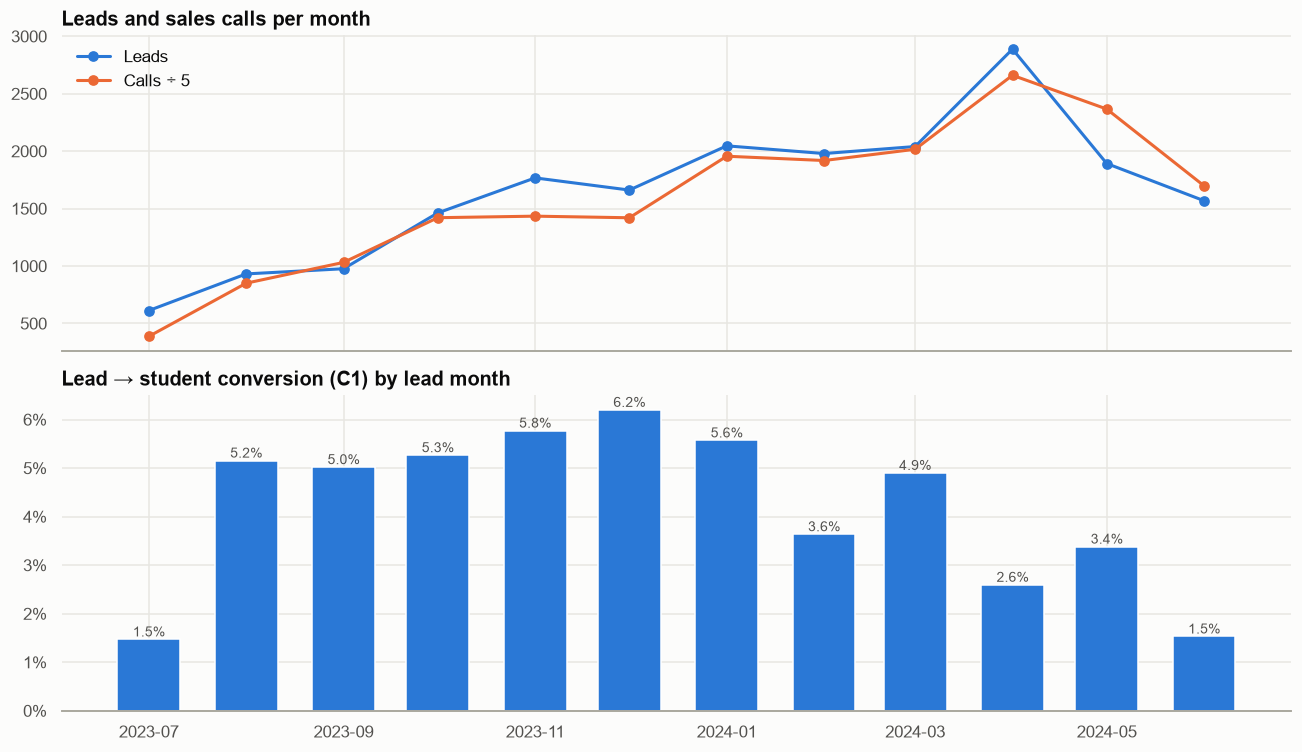

Корреляция лидов и звонков по месяцам: r = 0.94


In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(monthly.index, monthly["leads"], marker="o", color=PRIMARY, label="Leads")
axes[0].plot(monthly.index, monthly["calls"] / 5, marker="o", color=ACCENT, label="Calls ÷ 5")
axes[0].set_title("Leads and sales calls per month"); axes[0].legend(frameon=False, loc="upper left")
axes[1].bar(monthly.index, monthly["C1"], width=20, color=PRIMARY)
pct_axis(axes[1], decimals=0); axes[1].set_title("Lead → student conversion (C1) by lead month")
for x, v in zip(monthly.index, monthly["C1"]):
    axes[1].text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9, color=viz.TEXT_2)
plt.tight_layout(); save(fig, "02_time_series"); plt.show()
print(f"Корреляция лидов и звонков по месяцам: r = {monthly['leads'].corr(monthly['calls']):.2f}")

In [9]:
weekly = deals.set_index("created_time").resample("W")["id"].count().to_frame("leads")
weekly["calls"] = calls.set_index("call_start_time").resample("W")["id"].count()
weekly = weekly.dropna()
lagged = {f"лаг {l} нед.": weekly["leads"].corr(weekly["calls"].shift(-l)) for l in range(0, 4)}
pd.Series(lagged, name="corr(лиды, звонки)").to_frame()

,"corr(лиды, звонки)"
лаг 0 нед.,0.79
лаг 1 нед.,0.77
лаг 2 нед.,0.66
лаг 3 нед.,0.59


**Выводы:**
- Поток лидов вырос с ~600 до 2 000–2 900 в месяц (пик — апрель 2024, совпадает с пиком бюджета).
- Звонки почти синхронно повторяют поток лидов (r ≈ 0.94 по месяцам, максимум на нулевом лаге по неделям):
  отдел продаж масштабируется вместе с маркетингом, но **конверсия при этом падает**: 5–6% в августе 2023 – январе 2024 →
  2.6–3.4% в апреле–мае 2024. Рост трафика не превращается в рост продаж пропорционально.
- Падение C1 в мае–июне 2024 частично объясняется тем, что сделки ещё «не дозрели» (медиана цикла 17 дней,
  хвост — месяцы), поэтому последние 1–2 месяца сравнивать с остальными нужно осторожно.

### 2.2 Время закрытия сделок и длительность от создания до закрытия

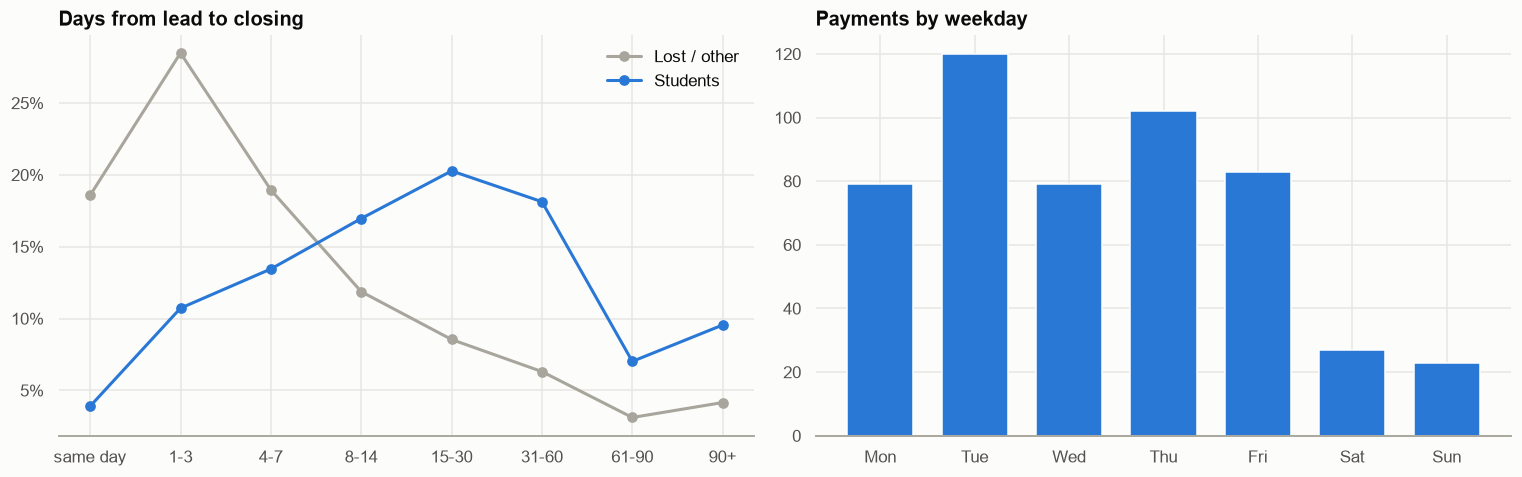

,count,mean,std,min,25%,50%,75%,max
is_student,,,,,,,,
False,"12,585.00",15.42,31.68,0.00,1.00,4.00,12.00,335.00
True,513.00,33.45,42.79,0.00,7.00,17.00,43.00,305.00


In [10]:
closed = deals.dropna(subset=["closing_date"])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins = [-1, 0, 3, 7, 14, 30, 60, 90, 400]
labels = ["same day", "1-3", "4-7", "8-14", "15-30", "31-60", "61-90", "90+"]
for status, color, lab in [(False, MUTED, "Lost / other"), (True, PRIMARY, "Students")]:
    part = closed[closed["is_student"] == status]
    share = pd.cut(part["deal_cycle_days"], bins, labels=labels).value_counts(normalize=True).sort_index()
    axes[0].plot(share.index.astype(str), share.values, marker="o", color=color, label=lab)
pct_axis(axes[0]); axes[0].set_title("Days from lead to closing"); axes[0].legend(frameon=False)
dow = students["closing_date"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
axes[1].bar(dow.index.str[:3], dow.values, color=PRIMARY, width=0.7)
axes[1].set_title("Payments by weekday")
plt.tight_layout(); save(fig, "02_closing"); plt.show()

closed.groupby("is_student")["deal_cycle_days"].describe()

**Выводы:**
- Проигранные сделки закрываются быстро (медиана — в первые дни: «не дозвонились» → Lost).
- Студенты платят в среднем через 2–5 недель: 50% — в течение 17 дней, 75% — в течение 43 дней.
  Значит, **оплата не годится как метрика двухнедельного A/B-теста** — за 14 дней её не успеет набрать даже
  половина будущих студентов. Нужна опережающая метрика (квалификация лида).
- По будням оплаты распределены ровно, на выходных — минимум: менеджеры не работают, сделки ждут.
- У 341 оплаченной сделки дата закрытия в исходных данных не заполнена — анализ цикла по 513 студентам.

## 3. Эффективность кампаний и источников
### 3.1 Источники: объём, качество лидов, конверсия, стоимость

In [11]:
AB = ["A - High", "B - Medium"]
src = deals.groupby("source", **OBS).agg(
    leads=("id", "size"), students=("is_student", "sum"), revenue=("revenue", "sum"),
    share_AB=("quality", lambda q: q.isin(AB).mean()))
src["spend"] = spend.groupby("source", **OBS)["spend"].sum().reindex(src.index).fillna(0)
src["C1"] = src["students"] / src["leads"]
src["CPL"] = src["spend"] / src["leads"]
src["CAC"] = (src["spend"] / src["students"]).replace(np.inf, np.nan)
src["ROMI"] = ((src["revenue"] - src["spend"]) / src["spend"]).replace(np.inf, np.nan)
src = src[src["leads"] > 10].sort_values("leads", ascending=False)
src.style.format({"share_AB": "{:.1%}", "C1": "{:.1%}", "CPL": "€{:.2f}", "CAC": "€{:,.0f}",
                  "ROMI": "{:.0%}", "revenue": "€{:,.0f}", "spend": "€{:,.0f}"}) \
   .background_gradient(subset=["C1", "share_AB"], cmap="Blues")

,leads,students,revenue,share_AB,spend,C1,CPL,CAC,ROMI
source,,,,,,,,,
Facebook Ads,4730,196,"€951,065",12.1%,"€33,755",4.1%,€7.14,€172,2718%
Google Ads,4114,168,"€737,230",9.8%,"€57,799",4.1%,€14.05,€344,1176%
Tiktok Ads,2003,56,"€217,795",6.0%,"€11,986",2.8%,€5.98,€214,1717%
SMM,1669,88,"€306,370",9.7%,"€7,270",5.3%,€4.36,€83,4114%
Youtube Ads,1618,53,"€217,000",7.8%,"€14,633",3.3%,€9.04,€276,1383%
Organic,1498,142,"€595,095",17.4%,€0,9.5%,€0.00,€0,nan%
CRM,1456,23,"€75,480",2.7%,€0,1.6%,€0.00,€0,nan%
Bloggers,1074,39,"€164,585",9.7%,"€13,439",3.6%,€12.51,€345,1125%
Telegram posts,993,39,"€155,850",10.9%,"€6,860",3.9%,€6.91,€176,2172%


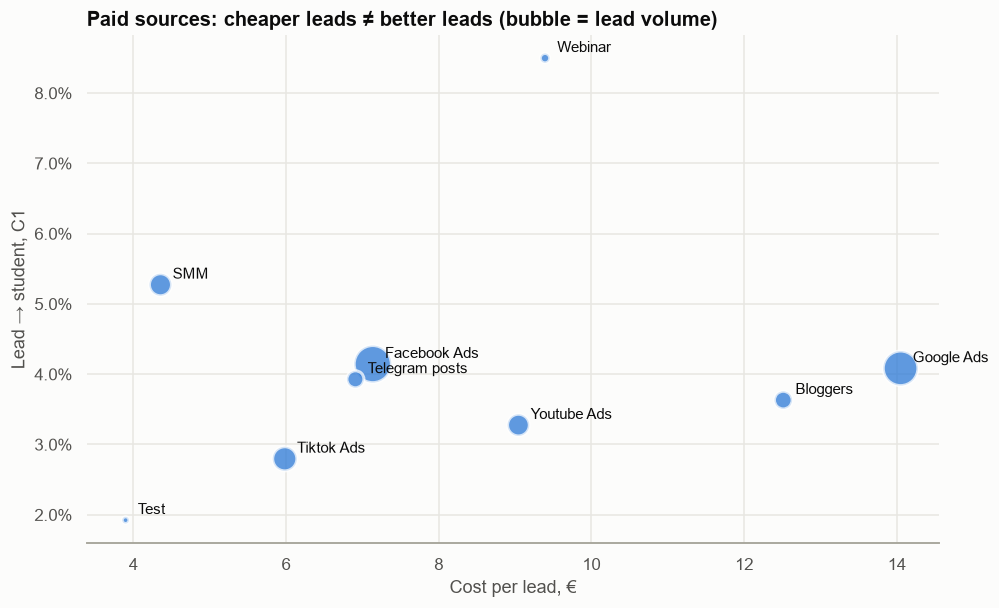

In [12]:
paid = src[src["spend"] > 0]
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(paid["CPL"], paid["C1"], s=paid["leads"] / 8, color=PRIMARY, alpha=0.75, edgecolor="white", lw=2)
for name, r in paid.iterrows():
    ax.annotate(name, (r["CPL"], r["C1"]), xytext=(8, 4), textcoords="offset points", fontsize=10, color=viz.TEXT)
pct_axis(ax, decimals=1); ax.set_xlabel("Cost per lead, €"); ax.set_ylabel("Lead → student, C1")
ax.set_title("Paid sources: cheaper leads ≠ better leads (bubble = lead volume)")
save(fig, "02_sources_scatter"); plt.show()

**Выводы по источникам:**
- **Organic** и **Webinar** — лучшая конверсия (9.5% и 8.5%) и самая высокая доля лидов A/B.
  Вебинар — самый эффективный *платный* канал: CAC ≈ €111.
- **Facebook Ads** — главный канал по объёму: дешёвый лид (€7) и средняя конверсия, CAC ≈ €172.
- **Google Ads** — лид в 2 раза дороже Facebook при той же конверсии → CAC ≈ €344, самый дорогой крупный канал.
- **TikTok** — дешёвые, но низкокачественные лиды (C1 2.8%, доля A/B 6%).
- **CRM** (повторные касания базы) почти не конвертируется (1.6%).

### 3.2 Кампании: генерация лидов и конверсия

In [13]:
camp = deals.groupby("campaign").agg(leads=("id", "size"), students=("is_student", "sum"),
                                     revenue=("revenue", "sum"))
camp["spend"] = spend.groupby("campaign")["spend"].sum()
camp["C1"] = camp["students"] / camp["leads"]
camp["CAC"] = camp["spend"] / camp["students"].replace(0, np.nan)
top_camp = camp[camp["leads"] >= 150].sort_values("leads", ascending=False)
print(f"Кампаний всего: {len(camp)}, с ≥150 лидами: {len(top_camp)} — они дают {top_camp['leads'].sum() / len(deals):.0%} лидов")
print(f"Кампаний из Deals, найденных в Spend: {camp.index.isin(spend['campaign']).mean():.0%}")
top_camp.style.format({"C1": "{:.1%}", "CAC": "€{:,.0f}", "revenue": "€{:,.0f}", "spend": "€{:,.0f}"}, na_rep="—") \
    .background_gradient(subset="C1", cmap="Blues")

Кампаний всего: 154, с ≥150 лидами: 22 — они дают 86% лидов
Кампаний из Deals, найденных в Spend: 30%


,leads,students,revenue,spend,C1,CAC
campaign,,,,,,
(no campaign),4239,263,"€1,024,310","€27,888",6.2%,€106
performancemax_digitalmarkt_ru_DE,2573,109,"€502,095",—,4.2%,—
youtube_shorts_DE,1596,53,"€217,000","€14,149",3.3%,€267
12.07.2023wide_DE,1531,48,"€197,385","€9,472",3.1%,€197
02.07.23wide_DE,943,52,"€268,790","€6,914",5.5%,€133
04.07.23recentlymoved_DE,734,30,"€114,040","€4,523",4.1%,€151
03.07.23women,595,29,"€159,150","€4,220",4.9%,€146
Dis_DE,567,29,"€146,245",—,5.1%,—
07.07.23LAL_DE,529,28,"€143,785","€4,200",5.3%,€150


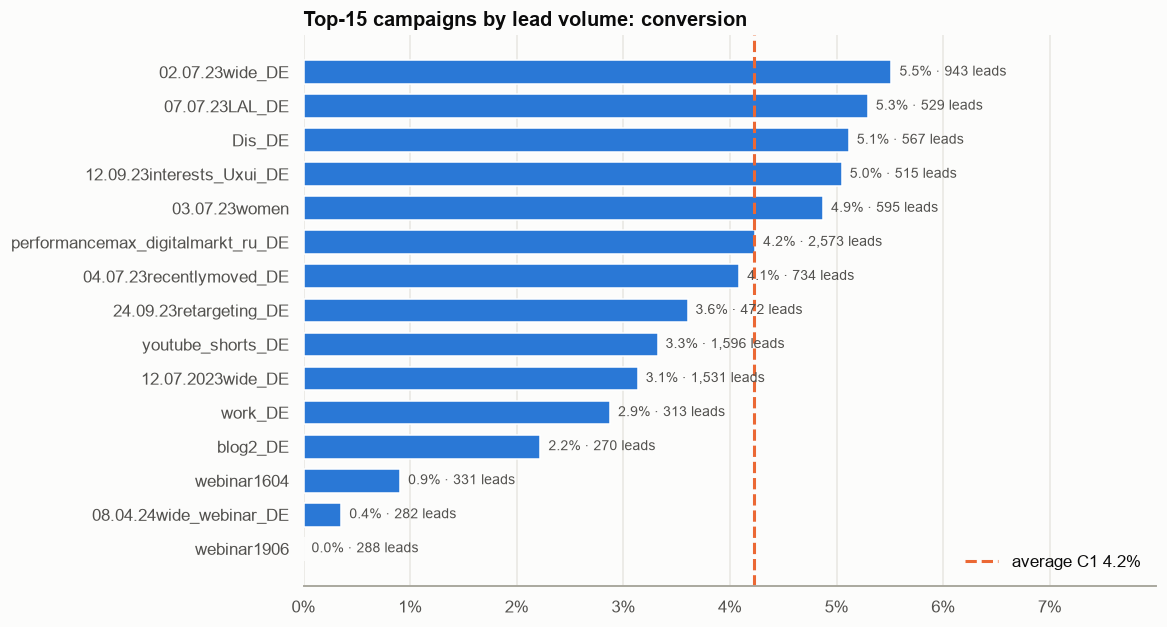

In [14]:
plot = top_camp.drop(index="(no campaign)").head(15).sort_values("C1")
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(plot.index, plot["C1"], color=PRIMARY, height=0.7)
ax.axvline(deals["is_student"].mean(), color=ACCENT, ls="--", lw=2, label=f"average C1 {deals['is_student'].mean():.1%}")
for i, (c1, n) in enumerate(zip(plot["C1"], plot["leads"])):
    ax.text(c1, i, f"  {c1:.1%} · {n:,} leads", va="center", fontsize=9, color=viz.TEXT_2)
pct_axis(ax, "x"); ax.set_xlim(0, plot["C1"].max() * 1.45); ax.legend(frameon=False, loc="lower right")
ax.set_title("Top-15 campaigns by lead volume: conversion"); ax.grid(axis="y", visible=False)
save(fig, "02_campaigns"); plt.show()

**Выводы по кампаниям:**
- `brand_search_eng_DE` (поиск по бренду) — 9.3%: люди уже знают школу.
- Широкие кампании Facebook (`02.07.23wide_DE`, `07.07.23LAL_DE`, `12.09.23interests_Uxui_DE`) — 5–5.5%, выше среднего.
- `performancemax_eng_DE` потратил ~€34k (23% всего бюджета!) и принёс 1 студента — **кандидат на отключение**.
- Вебинарные кампании (`webinar1604`, `webinar1906`, `08.04.24wide_webinar_DE`) дают много регистраций,
  но почти без оплат: регистрация на вебинар ≠ намерение купить.
- Только 29% названий кампаний из Deals есть в Spend (это 63% размеченных лидов) — расходы и лиды по
  многим кампаниям сопоставить нельзя. Нужна единая UTM-разметка.

## 4. Эффективность отдела продаж

In [15]:
own = deals.groupby("deal_owner_name", **OBS).agg(
    deals=("id", "size"), students=("is_student", "sum"), revenue=("revenue", "sum"),
    sla_median_h=("sla_sec", lambda s: s.median() / 3600),
    share_AB=("quality", lambda q: q.isin(AB).mean()))
own["C1"] = own["students"] / own["deals"]
own = own[own["deals"] >= 50].sort_values("revenue", ascending=False)
own.style.format({"C1": "{:.1%}", "share_AB": "{:.1%}", "revenue": "€{:,.0f}", "sla_median_h": "{:.1f}"}) \
    .background_gradient(subset=["C1"], cmap="Blues").background_gradient(subset=["sla_median_h"], cmap="Oranges")

,deals,students,revenue,sla_median_h,share_AB,C1
deal_owner_name,,,,,,
Charlie Davis,2799,148,"€596,355",4.4,9.5%,5.3%
Ulysses Adams,2069,140,"€551,025",4.8,8.4%,6.8%
Julia Nelson,2085,91,"€434,765",7.0,10.1%,4.4%
Oliver Taylor,160,50,"€384,575",2.9,56.9%,31.2%
Paula Underwood,1771,93,"€333,445",4.8,9.4%,5.3%
Quincy Vincent,1805,65,"€230,720",5.8,11.9%,3.6%
Victor Barnes,1187,44,"€191,530",5.6,9.2%,3.7%
Nina Scott,1218,45,"€178,400",9.1,9.3%,3.7%
Jane Smith,904,31,"€177,405",2.4,13.2%,3.4%


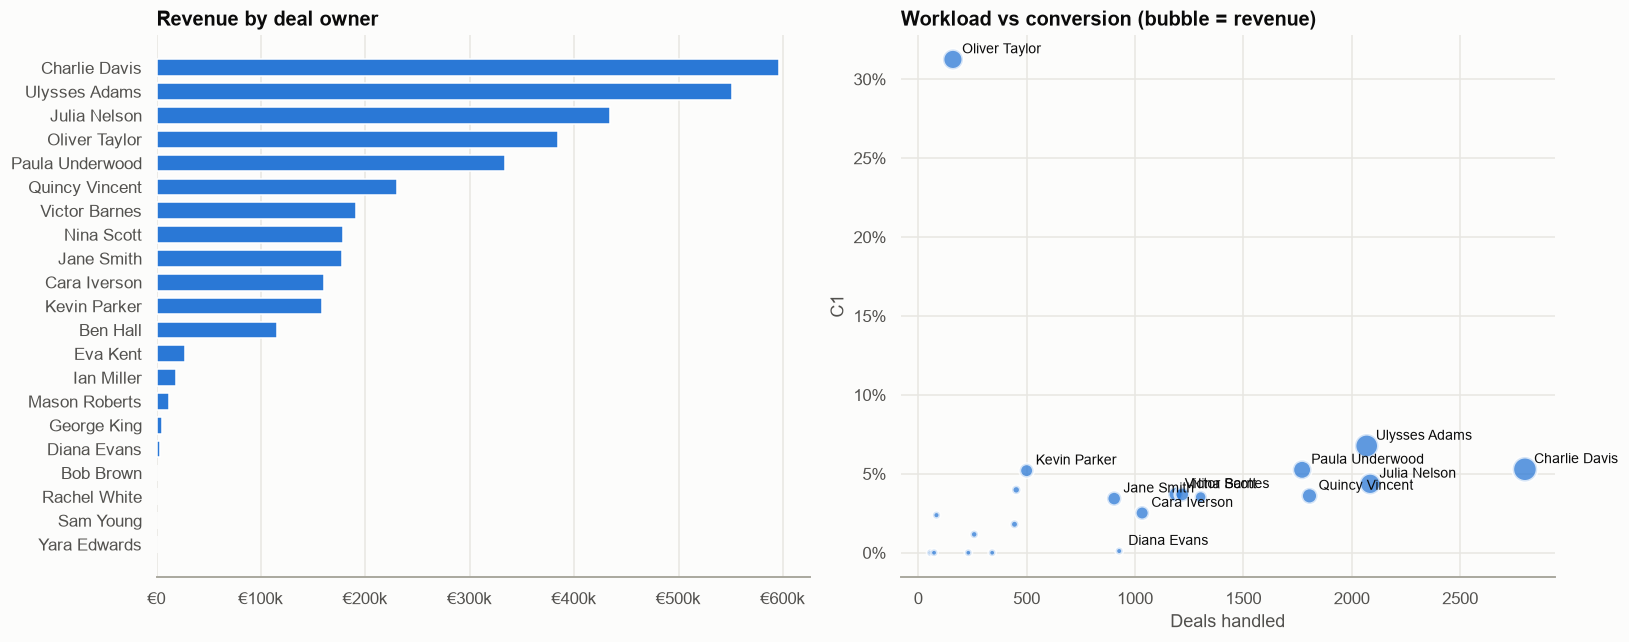

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
o = own.sort_values("revenue")
axes[0].barh(o.index.astype(str), o["revenue"], color=PRIMARY, height=0.7)
eur_axis(axes[0], "x"); axes[0].set_title("Revenue by deal owner"); axes[0].grid(axis="y", visible=False)
axes[1].scatter(own["deals"], own["C1"], s=own["revenue"] / 2500 + 20, color=PRIMARY, alpha=0.75, edgecolor="white", lw=2)
for name, r in own.iterrows():
    if r["revenue"] > 150_000 or r["C1"] > 0.1 or r["deals"] > 800 and r["C1"] < 0.02:
        axes[1].annotate(name, (r["deals"], r["C1"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
pct_axis(axes[1]); axes[1].set_xlabel("Deals handled"); axes[1].set_ylabel("C1")
axes[1].set_title("Workload vs conversion (bubble = revenue)")
plt.tight_layout(); save(fig, "02_sales_team"); plt.show()

In [17]:
cr_calls = calls.groupby("call_owner_name", **OBS).agg(
    calls=("id", "size"), talk_share=("is_conversation", "mean"), avg_talk_min=("duration_sec", lambda s: s.mean() / 60))
cr_calls = cr_calls[cr_calls["calls"] > 500].sort_values("calls", ascending=False)
cr_calls.style.format({"talk_share": "{:.1%}", "avg_talk_min": "{:.1f}", "calls": "{:,}"})

,calls,talk_share,avg_talk_min
call_owner_name,,,
Yara Edwards,"9,059",31.2%,1.6
Julia Nelson,"7,445",35.9%,3.4
Ian Miller,"7,215",34.7%,2.0
Charlie Davis,"7,213",36.1%,3.6
Diana Evans,"6,857",33.6%,3.1
Ulysses Adams,"6,085",36.8%,3.4
Amy Green,"5,982",29.2%,1.6
Nina Scott,"5,581",35.4%,2.1
Kevin Parker,"5,397",41.2%,2.1


**Выводы по отделу продаж:**
- Лидеры по выручке — **Charlie Davis** и **Ulysses Adams** (≈€1.15 млн на двоих, 32% выручки).
- **Oliver Taylor** — 31% конверсии на 160 сделках: судя по объёму и качеству, ему передают «тёплые»
  квалифицированные сделки (закрывающий менеджер). Сравнивать его C1 с остальными напрямую некорректно.
- **Diana Evans** (927 сделок, 1 студент), **Rachel White** и **Bob Brown** (0 студентов) — работают на
  первичной обработке/квалификации, а не на закрытии. Оценивать их нужно по доле квалифицированных лидов.
- Медианный SLA у менеджеров — от 2 до 12+ часов: разброс в 5 раз при одинаковом потоке.

## 5. Платежи и продукты
### 5.1 Типы оплаты и их влияние на успешность

In [18]:
with_pt = deals[deals["payment_type"].ne("Unknown")]
pt = with_pt.groupby("payment_type", **OBS).agg(
    deals=("id", "size"), students=("is_student", "sum"), revenue=("revenue", "sum"),
    avg_offer=("offer_total_amount", "mean"), avg_months=("months_of_study", "mean"))
pt["success_rate"] = pt["students"] / pt["deals"]
pt["revenue_per_student"] = pt["revenue"] / pt["students"].replace(0, np.nan)
pt.style.format({"success_rate": "{:.1%}", "revenue": "€{:,.0f}", "avg_offer": "€{:,.0f}",
                 "revenue_per_student": "€{:,.0f}", "avg_months": "{:.1f}"}, na_rep="—")

,deals,students,revenue,avg_offer,avg_months,success_rate,revenue_per_student
payment_type,,,,,,,
One Payment,137,110,"€309,035","€3,471",5.0,80.3%,"€2,809"
Recurring Payments,341,249,"€698,460","€5,180",6.1,73.0%,"€2,805"
Reservation,5,1,€100,"€3,100",1.0,20.0%,€100


- Тип оплаты указан только у 482 сделок (менеджеры заполняют его вручную и непоследовательно: у 57% студентов он пуст).
- **One Payment** — 80% успешных при указанном типе, **Recurring Payments** — 73%. Рассрочка — основной формат
  (2/3 студентов с известным типом) и приносит больше выручки на студента за счёт более дорогих 11-месячных курсов.
- **Reservation** (бронь) почти не конвертируется (1 из 5).

### 5.2 Популярность и успешность продуктов и типов обучения

In [19]:
known = deals[deals["product"].isin(["Digital Marketing", "UX/UI Design", "Web Developer"])]
prod = known.groupby(["product", "education_type"], **OBS).agg(
    leads=("id", "size"), students=("is_student", "sum"), revenue=("revenue", "sum"))
prod = prod[prod["leads"] > 20]
prod["C1"] = prod["students"] / prod["leads"]
prod["revenue_per_student"] = prod["revenue"] / prod["students"]
prod.style.format({"C1": "{:.1%}", "revenue": "€{:,.0f}", "revenue_per_student": "€{:,.0f}"}, na_rep="—")

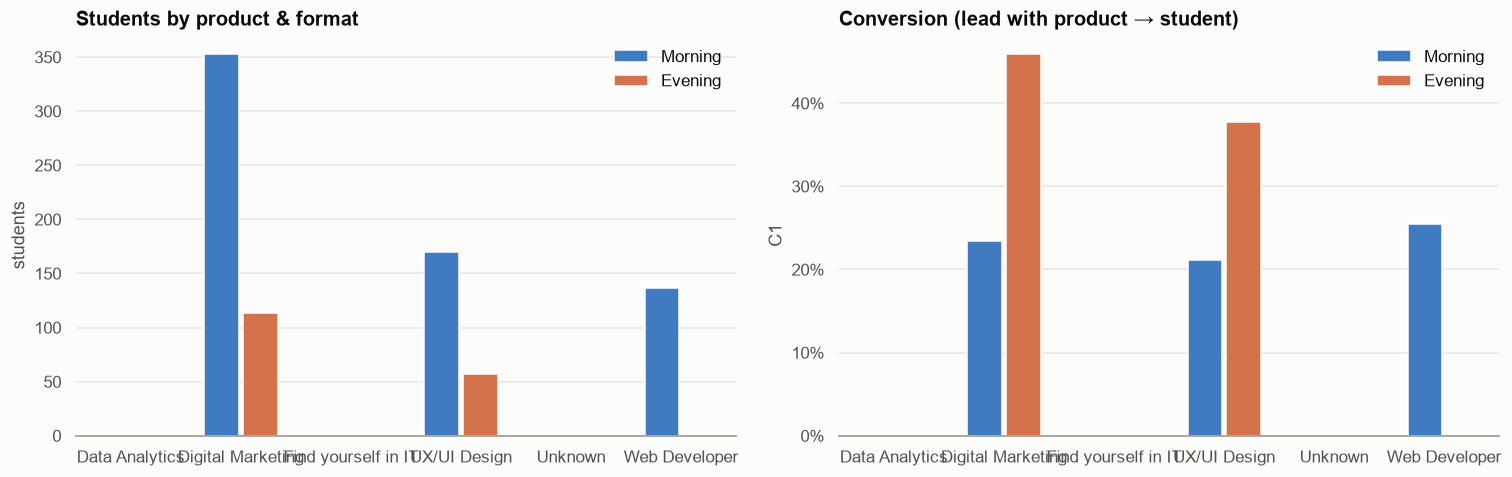

In [20]:
p2 = prod.reset_index()
p2 = p2[p2["education_type"].isin(["Morning", "Evening"])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(p2, x="product", y="students", hue="education_type", ax=axes[0],
            palette=[PRIMARY, ACCENT], hue_order=["Morning", "Evening"], width=0.7, gap=0.1)
axes[0].set_title("Students by product & format"); axes[0].set_xlabel(""); axes[0].legend(title="", frameon=False)
sns.barplot(p2, x="product", y="C1", hue="education_type", ax=axes[1],
            palette=[PRIMARY, ACCENT], hue_order=["Morning", "Evening"], width=0.7, gap=0.1)
pct_axis(axes[1]); axes[1].set_title("Conversion (lead with product → student)"); axes[1].set_xlabel("")
axes[1].legend(title="", frameon=False)
plt.tight_layout(); save(fig, "02_products"); plt.show()

**Выводы по продуктам:**
- **Digital Marketing** — самый популярный (57% студентов) и самый доходный продукт (€2.27 млн).
- Утренний формат преобладает (≈80% студентов), но **вечерние группы конвертируются лучше**
  (Digital Marketing 46% vs 23%, UX/UI 38% vs 21%) — вечер выбирают работающие люди с более
  осознанным решением. Вечерних групп для Web Developer практически нет — возможная ниша.
- Web Developer: короче (6 мес.) и дешевле → меньше выручки на студента (~€2.7k против ~€4.8k у DM).

## 6. Географический анализ
⚠️ Город и уровень немецкого заполнены только у ~11% сделок — менеджер вносит их на этапе консультации.
Поэтому C1 среди сделок с городом (≈33%) несопоставим с общей C1 (4.2%) — это **смещение выборки**, а не
«эффект города». Сравниваем города и уровни языка **между собой** внутри этой выборки.

In [21]:
geo = deals[deals["city"].ne("Unknown")]
print(geo["country"].value_counts().to_string())
city = geo.groupby("city").agg(deals=("id", "size"), students=("is_student", "sum"), revenue=("revenue", "sum"))
city["C1"] = city["students"] / city["deals"]
city = city.sort_values("deals", ascending=False)
city.head(15).style.format({"C1": "{:.1%}", "revenue": "€{:,.0f}"})

country
Germany       2132
Austria         13
Poland           9
Russia           3
Hungary          2
Uzbekistan       2
Slovakia         1
Unknown          0


,deals,students,revenue,C1
city,,,,
Berlin,182,78,"€373,760",42.9%
München,74,27,"€89,655",36.5%
Hamburg,62,22,"€84,495",35.5%
Leipzig,45,18,"€76,725",40.0%
Nürnberg,45,9,"€37,780",20.0%
Düsseldorf,33,7,"€38,040",21.2%
Dresden,28,9,"€28,350",32.1%
Frankfurt,27,7,"€24,200",25.9%
Dortmund,26,4,"€17,600",15.4%


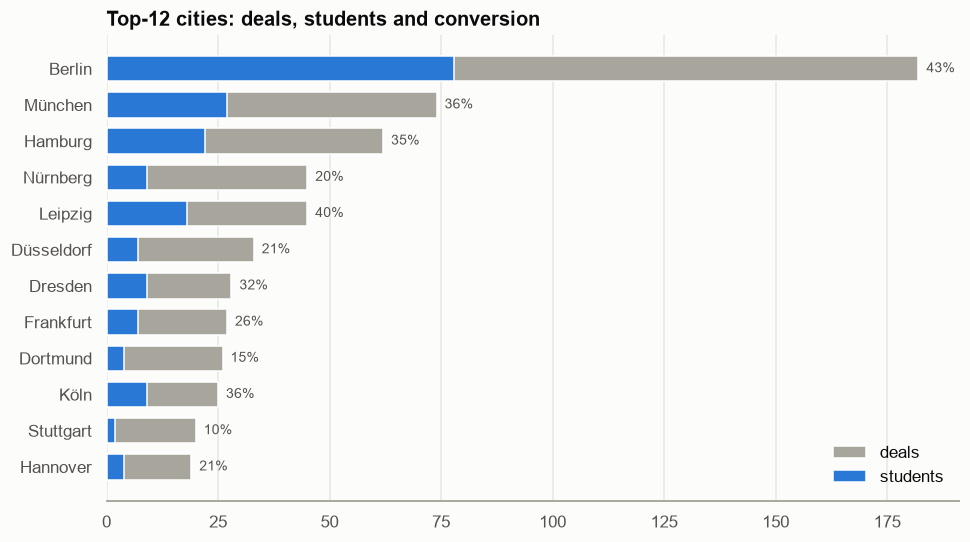

In [22]:
top = city.head(12).sort_values("deals")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index, top["deals"], color=MUTED, height=0.7, label="deals")
ax.barh(top.index, top["students"], color=PRIMARY, height=0.7, label="students")
for i, (n, s) in enumerate(zip(top["deals"], top["students"])):
    ax.text(n, i, f"  {s / n:.0%}", va="center", fontsize=9, color=viz.TEXT_2)
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
ax.set_title("Top-12 cities: deals, students and conversion")
save(fig, "02_cities"); plt.show()

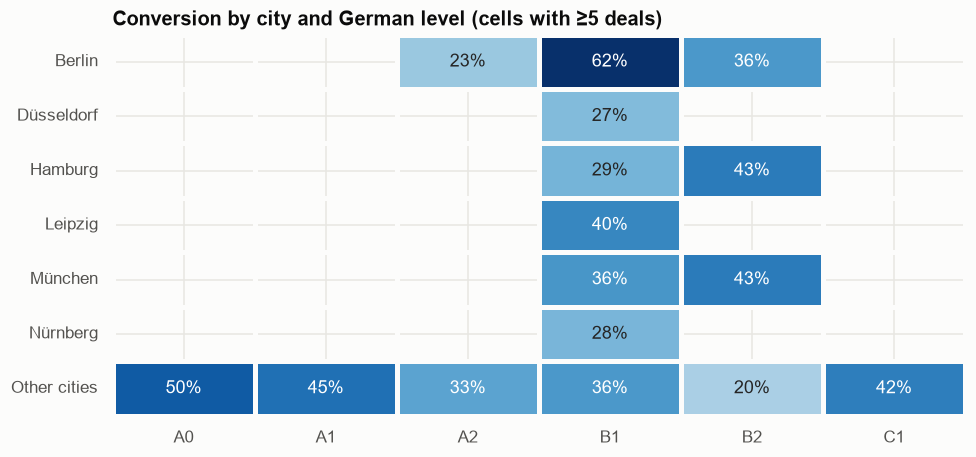

,deals,students,C1
german_level,,,
A0,9,4,44.4%
A1,22,10,45.5%
A2,125,40,32.0%
B1,682,253,37.1%
B2,140,35,25.0%
C1,24,10,41.7%


In [23]:
lvl_order = ["A0", "A1", "A2", "B1", "B2", "C1"]
g = geo[geo["german_level"].isin(lvl_order)].copy()
g["city_group"] = np.where(g["city"].isin(city.head(6).index), g["city"], "Other cities")
pivot_n = pd.crosstab(g["city_group"], g["german_level"]).reindex(columns=lvl_order, fill_value=0)
pivot_c1 = g.pivot_table(index="city_group", columns="german_level", values="is_student", aggfunc="mean",
                         observed=True).reindex(columns=lvl_order)
pivot_c1 = pivot_c1.where(pivot_n >= 5)  # не показываем ячейки с < 5 сделками

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(pivot_c1, annot=pivot_c1.map(lambda v: "" if pd.isna(v) else f"{v:.0%}"), fmt="",
            cmap="Blues", vmin=0, vmax=0.6, linewidths=2, linecolor="#fcfcfb", cbar=False, ax=ax)
ax.set_title("Conversion by city and German level (cells with ≥5 deals)"); ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "02_german_city"); plt.show()

lvl = g.groupby("german_level", **OBS).agg(deals=("id", "size"), students=("is_student", "sum"))
lvl["C1"] = lvl["students"] / lvl["deals"]
lvl.reindex(lvl_order).style.format({"C1": "{:.1%}"})

**Выводы по географии:**
- 99% клиентов с указанным городом живут в **Германии**; единично — Австрия и Польша.
- **Берлин** — крупнейший рынок (182 сделки) и лучшая конверсия среди крупных городов (43%), затем
  Мюнхен, Гамбург, Лейпциг. Стоит усилить гео-таргетинг на Берлин и крупные города.
- Самый сильный сегмент — **Берлин + B1**: 62% конверсии.
- **Уровень немецкого:** основная аудитория — **B1** (≈68% указанных). Конверсия при B1 (37%) выше, чем
  при B2 (25%) и A2 (30%). Люди с B2 чаще уже находят работу без переобучения, с A2 — сомневаются,
  справятся ли с курсом. Ядро аудитории — B1, на него стоит ориентировать коммуникацию.

## 7. Скорость реакции (SLA) и конверсия — мост к продуктовой аналитике

,leads,C1,share_AB,no_answer
sla_bucket,,,,
< 15 min,950,6.6%,21.2%,33.4%
15–60 min,2385,6.0%,13.9%,33.5%
1–4 h,3287,5.5%,12.6%,31.9%
4–24 h,6615,5.2%,10.7%,34.7%
> 24 h,1758,4.6%,13.6%,41.9%


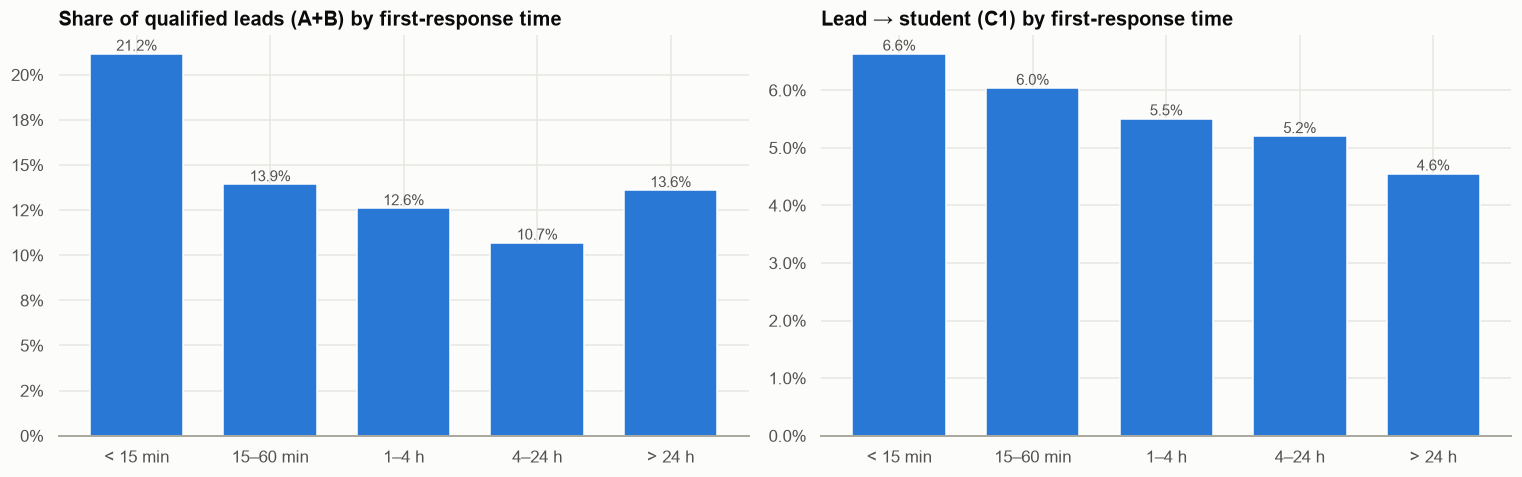

In [24]:
deals["sla_bucket"] = pd.cut(deals["sla_sec"] / 3600, [0, 0.25, 1, 4, 24, 1e6],
                             labels=["< 15 min", "15–60 min", "1–4 h", "4–24 h", "> 24 h"])
sla = deals.groupby("sla_bucket", **OBS).agg(
    leads=("id", "size"), C1=("is_student", "mean"), share_AB=("quality", lambda q: q.isin(AB).mean()),
    no_answer=("lost_reason", lambda l: l.isin(["Doesn't Answer", "Stopped Answering"]).mean()))
display(sla.style.format({"C1": "{:.1%}", "share_AB": "{:.1%}", "no_answer": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(sla.index.astype(str), sla["share_AB"], color=PRIMARY, width=0.7)
axes[0].set_title("Share of qualified leads (A+B) by first-response time"); pct_axis(axes[0])
axes[1].bar(sla.index.astype(str), sla["C1"], color=PRIMARY, width=0.7)
axes[1].set_title("Lead → student (C1) by first-response time"); pct_axis(axes[1], decimals=1)
for ax, col in zip(axes, ["share_AB", "C1"]):
    for i, v in enumerate(sla[col]):
        ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=10, color=viz.TEXT_2)
plt.tight_layout(); save(fig, "02_sla"); plt.show()

In [25]:
from scipy.stats import chi2_contingency
fast = deals["sla_bucket"].eq("< 15 min")
slow = deals["sla_bucket"].isin(["1–4 h", "4–24 h", "> 24 h"])
sub = deals[fast | slow]
table = pd.crosstab(fast[fast | slow], sub["quality"].isin(AB))
chi2, p, *_ = chi2_contingency(table)
print(f"Доля A+B: <15 мин = {sub[fast[fast | slow]]['quality'].isin(AB).mean():.1%}, "
      f"> 1 ч = {sub[~fast[fast | slow]]['quality'].isin(AB).mean():.1%}; χ² = {chi2:.1f}, p = {p:.1e}")

Доля A+B: <15 мин = 21.2%, > 1 ч = 11.7%; χ² = 72.1, p = 2.0e-17


**Ключевая находка:** лиды, которым ответили **быстрее 15 минут**, в 1.8 раза чаще становятся
квалифицированными (A+B: 21% против ~12%) и чаще покупают (C1 6.6% против 4.6% при ответе позже суток).
Разница статистически значима (χ², p ≪ 0.05). Это наблюдательные данные (корреляция, не причинность) —
поэтому эффект нужно **проверить A/B-тестом** (ноутбук 03).

## 8. Итоги EDA и рекомендации

| # | Находка | Рекомендация |
|---|---|---|
| 1 | C1 = 4.2%; 40% проигранных сделок — «не отвечает / перестал отвечать» | ускорить первый контакт, добавить мессенджеры/SMS к звонкам |
| 2 | Ответ < 15 мин → лидов A+B почти в 2 раза больше | A/B-тест «Speed-to-lead» (ноутбук 03) |
| 3 | Лиды выросли ×3, конверсия упала с 5–6% до 3.5% | масштабировать отдел продаж и контроль SLA вместе с бюджетом |
| 4 | `performancemax_eng_DE` — €34k и 1 студент; Google Ads CAC €344 | перераспределить бюджет в Facebook wide/LAL, вебинары, бренд-поиск |
| 5 | Вечерние группы конвертируются почти вдвое лучше | расширить вечерний формат, запустить вечерний Web Developer |
| 6 | Ядро — Берлин и уровень B1 | гео- и языковой таргетинг рекламы |
| 7 | 71% названий кампаний не сопоставляются со Spend, ключевые поля заполняются вручную | единая UTM-разметка и обязательные поля в CRM |

➡️ Следующий шаг — [03_unit_economics_ab_test.ipynb](03_unit_economics_ab_test.ipynb)